# 01 — TCM-SD exploratory data analysis (DS 340W)

**Research question:** How accurately can machine learning models classify TCM syndromes based on patients’ symptoms and clinical data?

**Dataset:** TCM-SD (Ren et al., CCL 2022)  
**Public link:** https://github.com/Borororo/ZY-BERT  
**Local path:** `data/raw/TCM-SD/`  
**License:** CC BY-NC-SA 4.0 (non-commercial research with attribution)

This notebook **does not train models**. It only loads, profiles, and visualizes the release so we can choose features, targets, and a classification framing.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 40)

ROOT = Path("..").resolve()
if not (ROOT / "data" / "raw" / "TCM-SD").exists():
    ROOT = Path(".").resolve()
DATA_DIR = ROOT / "data" / "raw" / "TCM-SD"
assert DATA_DIR.exists(), f"Missing {DATA_DIR}. Run: bash scripts/download_tcm_sd.sh"

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_DIR =", DATA_DIR)

DATA_DIR = /workspace/data/raw/TCM-SD


## 1. Load the dataset

TCM-SD ships as JSON Lines files: `train.json`, `dev.json`, `test.json`.  
If `train.json` / `dev.json` are missing after clone, unzip `TCM_SD_train_dev.zip` in the same folder.

In [2]:
def load_jsonl(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. From repo root run: "
            f"cd data/raw/TCM-SD && unzip -qo TCM_SD_train_dev.zip"
        )
    rows = []
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    frame = pd.DataFrame(rows)
    frame["split"] = path.stem
    return frame


train = load_jsonl(DATA_DIR / "train.json")
dev = load_jsonl(DATA_DIR / "dev.json")
test = load_jsonl(DATA_DIR / "test.json")
df = pd.concat([train, dev, test], ignore_index=True)

print("Split sizes:")
display(df["split"].value_counts().rename("n").to_frame())
display(df.head(3))

Split sizes:


,n
split,
train,43180
dev,5486
test,5486


,user_id,lcd_id,lcd_name,syndrome,chief_complaint,description,detection,norm_syndrome,split
0,479372,BNP120,吐血病,气虚不摄证,呕血2小时。,患者2小时前无明显诱因出现吐鲜血，色红，反酸、嗳气、烧心偶作，偶有恶心干呕，无发热，头晕偶作，无心慌胸闷，未进食，无便血，当时未予重视。于今晨6时再次吐鲜血，量约50mL，遂至我院就诊，门诊查“新型冠状病毒核酸试验未见明显异常。胸部...,6.中医四诊摘要：神志清晰，精神尚可，形体形体适中，语言清晰，口唇红润；皮肤正常，无斑疹。头颅大小形态正常，无目窼下陷，无白睛，耳轮正常，无耳瘘级生疮；颈部对称，无青筋暴露，无瘿瘤瘰疬，胸部对称，虚里搏动正常，腹部平坦，无癥瘕痞块，...,气虚不摄证,train
1,448409,BNP130,便血病,气虚不摄证,黑便间作一月余,患者一个月前无明显诱因出现出现大便发黑，伴上腹部不适，腹部隐痛，大便成形，无里急后重，无粘液附着，纳尚可，未予重视，在市三院予对症输血支持治疗，症状稍缓解，患者仍有头晕、乏力、双下肢无力、颈部及头痛反复发作，今为求进一步治疗遂由家人...,神志清晰，精神尚可，形体形体适中，语言清晰，口唇苍白；皮肤正常，无斑疹。头颅大小形态正常，无目窼下陷，无白睛，耳轮正常，无耳瘘级生疮；颈部对称，无青筋暴露，无瘿瘤瘰疬，胸部对称，虚里搏动正常，腹部平坦，无癥瘕痞块，爪甲色泽：色泽红润...,气虚不摄证,train
2,432415,BNP130,便血病,气虚不摄证,黑便四天,患者四天前无明显诱因出现大便发黑，成形，1-2次/天，无粘液脓血，伴里急后重，排气正常，食欲欠佳，进食量减退，恶心间作，无呕吐、反酸，夜寐欠佳，今为求进一步诊疗，门诊遂拟上消化道出血收入我科进一步诊治。发病来，患者解黑便，成形，无发...,神志清晰，精神尚可，形体形体适中，语言清晰，口唇苍白；皮肤正常，无斑疹。头颅大小形态正常，无目窼下陷，无白睛，耳轮正常，无耳瘘级生疮；颈部对称，无青筋暴露，无瘿瘤瘰疬，胸部对称，虚里搏动正常，腹部平坦，无癥瘕痞块，爪甲色泽：色泽红润...,气虚不摄证,train


## 2. Number of rows and columns

In [3]:
n_rows, n_cols = df.shape
print(f"Combined rows: {n_rows:,}")
print(f"Columns: {n_cols}")
print("Column names:", list(df.columns))

schema = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "nunique": df.nunique(dropna=True),
        "example": [df[c].dropna().astype(str).iloc[0][:80] if df[c].notna().any() else None for c in df.columns],
    }
)
display(schema)

Combined rows: 54,152
Columns: 9
Column names: ['user_id', 'lcd_id', 'lcd_name', 'syndrome', 'chief_complaint', 'description', 'detection', 'norm_syndrome', 'split']


,dtype,non_null,nunique,example
user_id,str,54152,52295,479372
lcd_id,str,54152,481,BNP120
lcd_name,str,54152,452,吐血病
syndrome,str,54152,282,气虚不摄证
chief_complaint,str,54152,36892,呕血2小时。
description,str,54152,46885,患者2小时前无明显诱因出现吐鲜血，色红，反酸、嗳气、烧心偶作，偶有恶心干呕，无发热，头晕偶作，无心慌胸闷，未进食，无便血，当时未予重视。于今晨6时再次吐鲜血，量
detection,str,54152,11239,6.中医四诊摘要：神志清晰，精神尚可，形体形体适中，语言清晰，口唇红润；皮肤正常，无斑疹。头颅大小形态正常，无目窼下陷，无白睛，耳轮正常，无耳瘘级生疮；颈部对称
norm_syndrome,str,54152,148,气虚不摄证
split,str,54152,3,train


## 3. Patient symptom / clinical features

TCM-SD is a **text** clinical-note benchmark. Symptom and four-examination information live in free-text fields (not a wide binary symptom matrix).

In [4]:
FEATURE_COLS = [
    "chief_complaint",  # concise main symptoms
    "description",      # admission / history narrative (clinical context + symptoms)
    "detection",        # four diagnostic methods template (inspection, listening, inquiry, palpation)
]

feature_profile = pd.DataFrame(
    {
        "role": [
            "Chief complaint (short symptom statement)",
            "Clinical history / course narrative",
            "Four-examination record (望闻问切-style template text)",
        ],
        "avg_chars": [df[c].astype(str).str.len().mean() for c in FEATURE_COLS],
        "median_chars": [df[c].astype(str).str.len().median() for c in FEATURE_COLS],
        "empty_or_na": [((df[c].isna()) | (df[c].astype(str).str.strip() == "")).sum() for c in FEATURE_COLS],
    },
    index=FEATURE_COLS,
)
display(feature_profile.round(1))

print("\nExample feature bundle (one row):")
sample = df.loc[0, FEATURE_COLS]
for col, text in sample.items():
    print(f"\n--- {col} ---")
    print(str(text)[:500])

,role,avg_chars,median_chars,empty_or_na
chief_complaint,Chief complaint (short symptom statement),13.4,13.0,19
description,Clinical history / course narrative,252.5,198.0,0
detection,Four-examination record (望闻问切-style template text),132.0,132.0,4



Example feature bundle (one row):

--- chief_complaint ---
呕血2小时。

--- description ---
患者2小时前无明显诱因出现吐鲜血，色红，反酸、嗳气、烧心偶作，偶有恶心干呕，无发热，头晕偶作，无心慌胸闷，未进食，无便血，当时未予重视。于今晨6时再次吐鲜血，量约50mL，遂至我院就诊，门诊查“新型冠状病毒核酸试验未见明显异常。胸部CT：右肺中叶陈旧性索条”，遂由门诊收入我科，入院时患者：吐血未作，反酸、嗳气、烧心偶作，偶有恶心干呕，无发热，头晕偶作，无心慌胸闷，未进食，无便血，近期体重无明显下降，舌红苔薄白，脉细弦。

--- detection ---
6.中医四诊摘要：神志清晰，精神尚可，形体形体适中，语言清晰，口唇红润；皮肤正常，无斑疹。头颅大小形态正常，无目窼下陷，无白睛，耳轮正常，无耳瘘级生疮；颈部对称，无青筋暴露，无瘿瘤瘰疬，胸部对称，虚里搏动正常，腹部平坦，无癥瘕痞块，爪甲色泽红润，双下肢对称，舌淡红，苔白，脉细。


## 4. Syndrome target labels

`syndrome` is the original string; `norm_syndrome` is the **normalized class label** used by the benchmark (preferred target).

In [5]:
TARGET = "norm_syndrome"
ALT_TARGET = "syndrome"

print("Usable syndrome targets: YES")
print(f"Primary target column: {TARGET}")
print(f"Unique {TARGET}:", df[TARGET].nunique())
print(f"Unique {ALT_TARGET}:", df[ALT_TARGET].nunique())
print(
    "Rows where syndrome != norm_syndrome:",
    int((df[ALT_TARGET].fillna("") != df[TARGET].fillna("")).sum()),
)

vocab_path = DATA_DIR / "syndrome_vocab.txt"
if vocab_path.exists():
    vocab = [line.strip() for line in vocab_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    print(f"syndrome_vocab.txt entries: {len(vocab)}")
    missing_from_vocab = sorted(set(df[TARGET]) - set(vocab))
    print("Labels in data but not in vocab:", missing_from_vocab[:10], "count=", len(missing_from_vocab))

display(df[[TARGET, ALT_TARGET]].value_counts().head(10).rename("n").reset_index())

Usable syndrome targets: YES
Primary target column: norm_syndrome
Unique norm_syndrome: 148
Unique syndrome: 282
Rows where syndrome != norm_syndrome: 6725
syndrome_vocab.txt entries: 148
Labels in data but not in vocab: [] count= 0


,norm_syndrome,syndrome,n
0,气虚血瘀证,气虚血瘀证,9225
1,湿热下注证,湿热下注证,8716
2,气滞血瘀证,气滞血瘀证,5204
3,风痰瘀阻证,风痰阻络证,3722
4,肝胃郁热证,肝胃郁热证,2233
5,痰湿蕴肺证,痰湿蕴肺证,2078
6,正虚瘀结证,正虚瘀结证,1928
7,热毒蕴结证,热毒蕴结证,1433
8,脾肾两虚证,脾肾两虚证,1102
9,肝肾亏虚证,肝肾亏虚证,994


## 5. Missing values

,n_na,pct_na,n_blank_str
user_id,0,0.0,0
lcd_id,0,0.0,0
lcd_name,0,0.0,0
syndrome,0,0.0,0
chief_complaint,0,0.0,19
description,0,0.0,0
detection,0,0.0,4
norm_syndrome,0,0.0,0
split,0,0.0,0


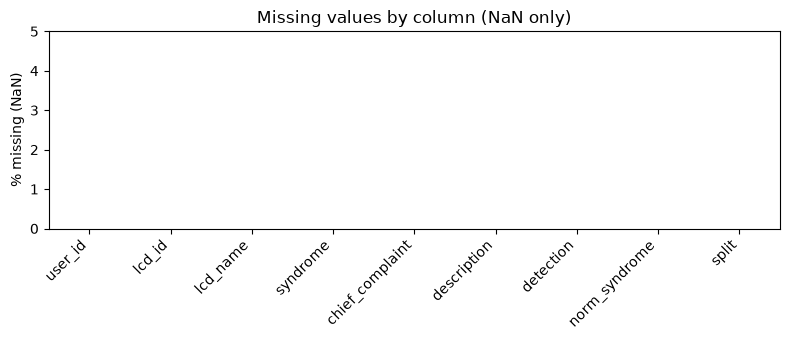

In [6]:
blank_counts = {}
for c in df.columns:
    if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
        blank_counts[c] = int((df[c].fillna("").astype(str).str.strip() == "").sum())
    else:
        blank_counts[c] = 0

missing = pd.DataFrame(
    {
        "n_na": df.isna().sum(),
        "pct_na": (100 * df.isna().mean()).round(3),
        "n_blank_str": pd.Series(blank_counts),
    }
)
display(missing)

fig, ax = plt.subplots(figsize=(8, 3.5))
missing["pct_na"].plot(kind="bar", ax=ax, color="#2f6f6a")
ax.set_ylabel("% missing (NaN)")
ax.set_title("Missing values by column (NaN only)")
ax.set_ylim(0, max(5, float(missing["pct_na"].max()) + 1))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "missing_values.png", dpi=120)
plt.show()


## 6. Duplicates

Check exact row duplicates and duplicate clinical text that could inflate accuracy if split carelessly.

In [7]:
content_cols = ["chief_complaint", "description", "detection", "norm_syndrome"]

dup_report = pd.Series(
    {
        "exact_full_row_duplicates": int(df.duplicated().sum()),
        "duplicate_user_id": int(df["user_id"].duplicated().sum()),
        "duplicate_feature_text_only": int(df.duplicated(subset=FEATURE_COLS).sum()),
        "duplicate_features_plus_label": int(df.duplicated(subset=content_cols).sum()),
    }
)
display(dup_report.to_frame("count"))

if df.duplicated(subset=FEATURE_COLS).any():
    print("Example duplicated feature texts (same symptoms/clinical fields, possibly different IDs):")
    dup_mask = df.duplicated(subset=FEATURE_COLS, keep=False)
    display(
        df.loc[dup_mask, ["user_id", "split", "norm_syndrome", "chief_complaint"]]
        .sort_values(["chief_complaint", "user_id"])
        .head(8)
    )

,count
exact_full_row_duplicates,9
duplicate_user_id,1857
duplicate_feature_text_only,5977
duplicate_features_plus_label,5640


Example duplicated feature texts (same symptoms/clinical fields, possibly different IDs):


,user_id,split,norm_syndrome,chief_complaint
49850,471955,test,湿热下注证,",肛内肿物外脱伴肿痛2年"
49851,471955,test,湿热下注证,",肛内肿物外脱伴肿痛2年"
27506,433113,train,肝胃郁热证,上腹不适2年余，加重1月
28122,454377,train,肝胃郁热证,上腹不适2年余，加重1月
28228,417185,train,肝胃郁热证,上腹疼痛1周
52147,433913,test,肝胃郁热证,上腹疼痛1周
27588,441152,train,肝胃郁热证,上腹疼痛1周
27679,446786,train,肝胃郁热证,上腹疼痛1周


## 7. Syndrome frequency distributions

Long-tail imbalance is expected in real clinical SD data and matters for metrics (prefer macro-F1 / balanced accuracy later — not done here).

,n_classes,min_count,median_count,mean_count,max_count,top_class,top_class_n,top_class_pct
0,148,11,58.5,365.891892,9226,气虚血瘀证,9226,17.04


/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 33033 (\N{CJK UNIFIED IDEOGRAPH-8109}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 30201 (\N{CJK UNIFIED IDEOGRAPH-75F9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 38459 (\N{CJK UNIFIED IDEOGRAPH-963B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 30192 (\N{CJK UNIFIED IDEOGRAPH-75F0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18123/4224187703.py:28: UserWarning: Glyph 30208 (\N{CJK UNIFIED IDEOGRAP

/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33033 (\N{CJK UNIFIED IDEOGRAPH-8109}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30201 (\N{CJK UNIFIED IDEOGRAPH-75F9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38459 (\N{CJK UNIFIED IDEOGRAPH-963B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/ubuntu/.local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) m

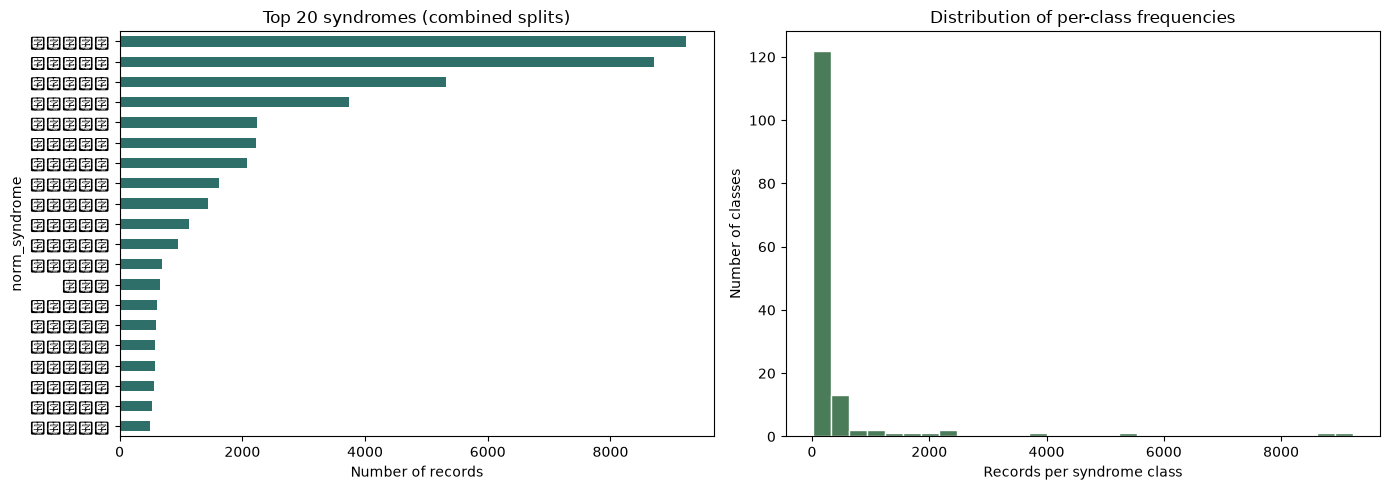

Top 10 classes:


,n
norm_syndrome,
气虚血瘀证,9226
湿热下注证,8716
气滞血瘀证,5324
风痰瘀阻证,3732
肝胃郁热证,2233
正虚瘀结证,2215
痰湿蕴肺证,2084
肝肾亏虚证,1619
热毒蕴结证,1436


Bottom 10 classes:


,n
norm_syndrome,
热毒壅结证,13
阴虚湿热证,13
寒痰阻肺证,13
风痰闭阻证,12
脾胃湿热证,12
毒邪流窜证,12
瘀血内阻证,11
气血失调证,11
肾阳虚证,11


,split,norm_syndrome,n
25,dev,气虚血瘀证,923
37,dev,湿热下注证,872
20,dev,气滞血瘀证,533
143,dev,风痰瘀阻证,374
80,dev,肝胃郁热证,224
173,test,气虚血瘀证,923
185,test,湿热下注证,872
168,test,气滞血瘀证,533
291,test,风痰瘀阻证,374
228,test,肝胃郁热证,224


In [8]:
label_counts = df[TARGET].value_counts()
label_summary = pd.DataFrame(
    {
        "n_classes": [label_counts.shape[0]],
        "min_count": [int(label_counts.min())],
        "median_count": [float(label_counts.median())],
        "mean_count": [float(label_counts.mean())],
        "max_count": [int(label_counts.max())],
        "top_class": [label_counts.index[0]],
        "top_class_n": [int(label_counts.iloc[0])],
        "top_class_pct": [round(100 * label_counts.iloc[0] / len(df), 2)],
    }
)
display(label_summary)

top_k = 20
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

label_counts.head(top_k).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2f6f6a")
axes[0].set_title(f"Top {top_k} syndromes (combined splits)")
axes[0].set_xlabel("Number of records")

axes[1].hist(label_counts.values, bins=30, color="#4a7c59", edgecolor="white")
axes[1].set_title("Distribution of per-class frequencies")
axes[1].set_xlabel("Records per syndrome class")
axes[1].set_ylabel("Number of classes")

plt.tight_layout()
fig.savefig(FIG_DIR / "syndrome_frequency.png", dpi=120)
plt.show()

print("Top 10 classes:")
display(label_counts.head(10).rename("n").to_frame())
print("Bottom 10 classes:")
display(label_counts.tail(10).rename("n").to_frame())

# Per-split top classes
split_top = (
    df.groupby(["split", TARGET]).size().rename("n").reset_index()
    .sort_values(["split", "n"], ascending=[True, False])
)
display(split_top.groupby("split").head(5))

## 8. Classification task type: binary, multiclass, or multi-label?

Decision rule used here:
- **Binary:** exactly 2 classes
- **Multiclass:** one discrete label per row, >2 classes
- **Multi-label:** each row can carry a *set* of labels (list/multi-hot)

In [9]:
n_classes = df[TARGET].nunique()
labels_are_atomic = df[TARGET].map(lambda x: isinstance(x, str)).all()
looks_like_list = df[TARGET].astype(str).str.contains(r"[;,|]|\[").mean()

if not labels_are_atomic:
    task = "multi-label (or structured labels) — inspect format"
elif n_classes == 2:
    task = "binary"
elif n_classes > 2:
    task = "multiclass (single-label)"
else:
    task = "undefined"

task_table = pd.DataFrame(
    [
        {"check": "Rows", "value": f"{len(df):,}"},
        {"check": "Unique norm_syndrome", "value": n_classes},
        {"check": "One label string per row?", "value": bool(labels_are_atomic)},
        {"check": "Share of labels looking like lists", "value": round(float(looks_like_list), 4)},
        {"check": "Supported task framing", "value": task},
    ]
)
display(task_table)

print(
    "\nConclusion: TCM-SD supports **single-label multiclass** syndrome classification "
    f"with {n_classes} classes. It is not multi-label in the release files "
    "(each record has one norm_syndrome). It is not binary."
)

,check,value
0,Rows,"54,152"
1,Unique norm_syndrome,148
2,One label string per row?,True
3,Share of labels looking like lists,0.0
4,Supported task framing,multiclass (single-label)



Conclusion: TCM-SD supports **single-label multiclass** syndrome classification with 148 classes. It is not multi-label in the release files (each record has one norm_syndrome). It is not binary.


## Identifiers, leakage risk, and columns to use for prediction

In [10]:
id_like = ["user_id", "lcd_id", "lcd_name"]
leakage_candidates = ["syndrome", "norm_syndrome"]  # direct targets / near-targets

column_roles = pd.DataFrame(
    [
        {"column": "user_id", "use_as_feature?": "No", "note": "Patient/record identifier — drop from model inputs; may use only for deduping/grouping."},
        {"column": "lcd_id", "use_as_feature?": "Usually no", "note": "Disease code. Strongly correlated with syndrome in practice → high leakage risk if the RQ is symptoms→syndrome."},
        {"column": "lcd_name", "use_as_feature?": "Usually no", "note": "Disease name. Same leakage concern as lcd_id for a pure syndrome-from-symptoms study."},
        {"column": "chief_complaint", "use_as_feature?": "Yes", "note": "Primary symptom text feature."},
        {"column": "description", "use_as_feature?": "Yes", "note": "Clinical narrative with symptoms/course."},
        {"column": "detection", "use_as_feature?": "Yes", "note": "Four-examination clinical text."},
        {"column": "syndrome", "use_as_feature?": "No", "note": "Raw label string — target leakage if used as input."},
        {"column": "norm_syndrome", "use_as_feature?": "No — TARGET", "note": "Normalized syndrome class to predict."},
        {"column": "split", "use_as_feature?": "No", "note": "Train/dev/test partition marker added by this notebook."},
    ]
)
display(column_roles)

print("Identifier present: user_id (yes).")
print("Direct label leakage columns: syndrome, norm_syndrome (must not be model inputs).")
print(
    "Potential indirect leakage: lcd_id / lcd_name encode disease context that can shortcut "
    "symptom-based syndrome reasoning. For the stated research question, prefer text features only."
)

# Quick association check: how predictive is disease name of syndrome (information overlap)
disease_mode = (
    df.groupby("lcd_name")
    .agg(n=(TARGET, "size"), n_syndromes=(TARGET, "nunique"))
    .sort_values("n", ascending=False)
)
top_by_disease = df.groupby("lcd_name")[TARGET].agg(lambda s: s.value_counts().index[0]).rename("top_syndrome")
disease_mode = disease_mode.join(top_by_disease)
display(disease_mode.head(10))
print(
    "Mean unique syndromes per disease name:",
    round(disease_mode["n_syndromes"].mean(), 2),
    "→ disease identity is informative; treat as leakage-prone for symptom-only RQ.",
)

,column,use_as_feature?,note
0,user_id,No,Patient/record identifier — drop from model inputs; may use only for deduping/grouping.
1,lcd_id,Usually no,Disease code. Strongly correlated with syndrome in practice → high leakage risk if the RQ is symptoms→syndrome.
2,lcd_name,Usually no,Disease name. Same leakage concern as lcd_id for a pure syndrome-from-symptoms study.
3,chief_complaint,Yes,Primary symptom text feature.
4,description,Yes,Clinical narrative with symptoms/course.
5,detection,Yes,Four-examination clinical text.
6,syndrome,No,Raw label string — target leakage if used as input.
7,norm_syndrome,No — TARGET,Normalized syndrome class to predict.
8,split,No,Train/dev/test partition marker added by this notebook.


Identifier present: user_id (yes).
Direct label leakage columns: syndrome, norm_syndrome (must not be model inputs).
Potential indirect leakage: lcd_id / lcd_name encode disease context that can shortcut symptom-based syndrome reasoning. For the stated research question, prefer text features only.


,n,n_syndromes,top_syndrome
lcd_name,,,
中风病,5767,36,气虚血瘀证
混合痔,3205,4,湿热下注证
胸痹心痛病,3169,16,气虚血瘀证
中风-中经络,2789,24,气虚血瘀证
眩晕病,2204,35,气虚血瘀证
消渴病,2114,23,气阴两虚证
内科癌病,2006,23,正虚瘀结证
肛肠病（混合痔病）,1799,9,湿热下注证
肛漏病,1568,2,湿热下注证


Mean unique syndromes per disease name: 4.48 → disease identity is informative; treat as leakage-prone for symptom-only RQ.


## Final recommendation for modeling (later notebooks)

| Item | Choice |
|------|--------|
| Dataset | TCM-SD — usable syndrome targets present (`norm_syndrome`) |
| Task | **Multiclass**, single-label (148 classes) |
| **X (features)** | `chief_complaint` + `description` + `detection` (concatenate or multi-field text model) |
| **y (target)** | `norm_syndrome` |
| Drop / do not use as features | `user_id`, `syndrome`, `norm_syndrome` (as input), preferably also `lcd_id` / `lcd_name` for a symptoms-only RQ |
| Splits | Prefer official `train` / `dev` / `test` files |

**Stop condition:** Not triggered — this dataset **does** contain usable syndrome targets, so no alternate dataset is required for EDA.

No models were trained in this notebook.